# Home Credit — agrégations, pipeline et comparaison de modèles

Ce notebook agrège les historiques `bureau`, `previous_application` et `installments_payments` au niveau de `SK_ID_CURR`, les joint à `application_train`, puis compare une régression logistique, une Random Forest et XGBoost.

**Anti-fuite :** la cible n'entre jamais dans les agrégations. Le jeu est séparé en train/validation avant l'ajustement des imputations, du scaler et de l'encodage ; ces transformations sont encapsulées dans chaque `Pipeline`. La validation sert uniquement à la comparaison, avec un seuil fixe de 0,5.

Le notebook lit les CSV secondaires en sélectionnant les colonnes utiles. Les modèles et rapports générés sont écrits localement dans les dossiers ignorés par Git.

In [1]:
from pathlib import Path
import gc
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data" / "raw").exists():
    ROOT_DIR = ROOT_DIR.parent
sys.path.insert(0, str(ROOT_DIR))

from src.data.home_credit import clean_application_data
from src.features.home_credit import (
    aggregate_bureau,
    aggregate_installments,
    aggregate_previous_applications,
    merge_historical_features,
)
from src.pipelines.home_credit import make_preprocessor

RAW_DIR = ROOT_DIR / "data" / "raw" / "home_credit"
REPORT_DIR = ROOT_DIR / "reports" / "generated"
MODEL_DIR = ROOT_DIR / "models"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f"Données : {RAW_DIR}")

Données : /home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/data/raw/home_credit


## 1. Préparer la table principale

Le nettoyage remplace uniquement le code anormal de `DAYS_EMPLOYED`, tout en gardant un indicateur. Les lignes avec identifiant dupliqué provoquent une erreur plutôt qu'une suppression implicite.

In [2]:
applications = pd.read_csv(RAW_DIR / "application_train.csv", low_memory=False)
applications = clean_application_data(applications)
target = applications["TARGET"].astype("int8")
print(f"Dossiers : {len(applications):,}; défauts : {target.sum():,} ({target.mean():.2%})")
print(f"Colonnes après nettoyage : {applications.shape[1]}")

Dossiers : 307,511; défauts : 24,825 (8.07%)
Colonnes après nettoyage : 123


## 2. Agréger les tables d'historique

Chaque agrégation ramène les enregistrements à une ligne par client. Seuls des faits historiques sont résumés ; aucune agrégation n'utilise `TARGET`. Les fichiers bruts sont libérés après leur agrégation pour limiter la mémoire.

In [3]:
bureau_columns = [
    "SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
    "CREDIT_DAY_OVERDUE", "DAYS_CREDIT_ENDDATE", "AMT_CREDIT_MAX_OVERDUE",
    "CNT_CREDIT_PROLONG", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_LIMIT", "AMT_CREDIT_SUM_OVERDUE", "DAYS_CREDIT_UPDATE",
    "AMT_ANNUITY",
]
bureau_raw = pd.read_csv(RAW_DIR / "bureau.csv", usecols=bureau_columns, low_memory=False)
bureau_features = aggregate_bureau(bureau_raw)
print(f"Bureau : {len(bureau_raw):,} lignes → {bureau_features.shape[0]:,} clients, {bureau_features.shape[1]} variables")
del bureau_raw
gc.collect()

Bureau : 1,716,428 lignes → 305,811 clients, 60 variables


0

In [4]:
previous_columns = [
    "SK_ID_CURR", "NAME_CONTRACT_STATUS", "AMT_APPLICATION", "AMT_CREDIT",
    "AMT_DOWN_PAYMENT", "AMT_GOODS_PRICE", "AMT_ANNUITY", "DAYS_DECISION",
    "CNT_PAYMENT", "RATE_DOWN_PAYMENT",
]
previous_raw = pd.read_csv(
    RAW_DIR / "previous_application.csv", usecols=previous_columns, low_memory=False
)
previous_features = aggregate_previous_applications(previous_raw)
print(f"Demandes précédentes : {len(previous_raw):,} lignes → {previous_features.shape[0]:,} clients, {previous_features.shape[1]} variables")
del previous_raw
gc.collect()

Demandes précédentes : 1,670,214 lignes → 338,857 clients, 45 variables


0

In [5]:
installment_columns = [
    "SK_ID_CURR", "AMT_INSTALMENT", "AMT_PAYMENT",
    "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT",
]
installments_raw = pd.read_csv(
    RAW_DIR / "installments_payments.csv", usecols=installment_columns, low_memory=False
)
installment_features = aggregate_installments(installments_raw)
print(f"Échéances : {len(installments_raw):,} lignes → {installment_features.shape[0]:,} clients, {installment_features.shape[1]} variables")
del installments_raw
gc.collect()

Échéances : 13,605,401 lignes → 339,587 clients, 26 variables


0

In [6]:
model_data = merge_historical_features(
    applications,
    bureau_features=bureau_features,
    previous_application_features=previous_features,
    installment_features=installment_features,
)
assert len(model_data) == len(applications)
assert model_data["SK_ID_CURR"].is_unique
print(f"Table modélisation : {model_data.shape[0]:,} lignes × {model_data.shape[1]} colonnes")

del applications, bureau_features, previous_features, installment_features
gc.collect()

Table modélisation : 307,511 lignes × 254 colonnes


0

## 3. Séparation et pipeline anti-fuite

L'identifiant n'est pas une variable prédictive. La séparation stratifiée précède l'apprentissage des médianes, du scaler et des catégories du OneHotEncoder. Les catégories jamais vues à l'entraînement sont ignorées à la validation.

In [7]:
X = model_data.drop(columns=["TARGET", "SK_ID_CURR"])
y = model_data["TARGET"].astype("int8")
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
del model_data, X, y
gc.collect()

print(f"Train : {X_train.shape}; validation : {X_valid.shape}")
print(f"Taux de défaut train : {y_train.mean():.2%}; validation : {y_valid.mean():.2%}")
print(f"Préprocesseur numérique : {X_train.select_dtypes(include='number').shape[1]} colonnes")
print(f"Préprocesseur catégoriel : {X_train.select_dtypes(exclude='number').shape[1]} colonnes")

Train : (246008, 252); validation : (61503, 252)
Taux de défaut train : 8.07%; validation : 8.07%
Préprocesseur numérique : 236 colonnes
Préprocesseur catégoriel : 16 colonnes


## 4. Entraîner et comparer les modèles

Les pondérations de classe sont calculées sur le train seulement. Les métriques sont calculées sur la validation, au seuil fixe de 0,5 pour rappel, précision et matrice de confusion. L'Average Precision résume la courbe précision-rappel et est reportée sous l'intitulé PR-AUC/AP.

In [8]:
class_weight_ratio = (y_train.eq(0).sum() / y_train.eq(1).sum())
models = {
    "Régression logistique": LogisticRegression(
        class_weight="balanced", max_iter=400, n_jobs=4,
        random_state=42, solver="saga", tol=1e-3,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=14, min_samples_leaf=20,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=4, random_state=42,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
        reg_lambda=2, scale_pos_weight=class_weight_ratio,
        tree_method="hist", max_bin=128, eval_metric="aucpr",
        n_jobs=4, random_state=42, verbosity=0,
    ),
}

pipelines = {}
probabilities = {}
metric_rows = []
confusion_matrices = {}
for model_name, estimator in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", make_preprocessor(X_train)),
            ("classifier", estimator),
        ]
    )
    print(f"Entraînement : {model_name}")
    pipeline.fit(X_train, y_train)
    scores = pipeline.predict_proba(X_valid)[:, 1]
    predictions = (scores >= 0.5).astype("int8")
    matrix = confusion_matrix(y_valid, predictions, labels=[0, 1])
    probabilities[model_name] = scores
    pipelines[model_name] = pipeline
    confusion_matrices[model_name] = matrix
    metric_rows.append(
        {
            "modèle": model_name,
            "ROC_AUC": roc_auc_score(y_valid, scores),
            "PR_AUC_average_precision": average_precision_score(y_valid, scores),
            "rappel_seuil_0_5": recall_score(y_valid, predictions, zero_division=0),
            "precision_seuil_0_5": precision_score(y_valid, predictions, zero_division=0),
            "vrais_négatifs": matrix[0, 0],
            "faux_positifs": matrix[0, 1],
            "faux_négatifs": matrix[1, 0],
            "vrais_positifs": matrix[1, 1],
        }
    )

comparison = pd.DataFrame(metric_rows).set_index("modèle").sort_values(
    "PR_AUC_average_precision", ascending=False
)
display(comparison.round(4))

Entraînement : Régression logistique


/home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=4', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Entraînement : Random Forest
Entraînement : XGBoost


,ROC_AUC,PR_AUC_average_precision,rappel_seuil_0_5,precision_seuil_0_5,vrais_négatifs,faux_positifs,faux_négatifs,vrais_positifs
modèle,,,,,,,,
XGBoost,0.7805,0.2792,0.6846,0.1852,41584,14954,1566,3399
Régression logistique,0.7662,0.2500,0.6979,0.1689,39485,17053,1500,3465
Random Forest,0.7479,0.2232,0.4393,0.2156,48604,7934,2784,2181


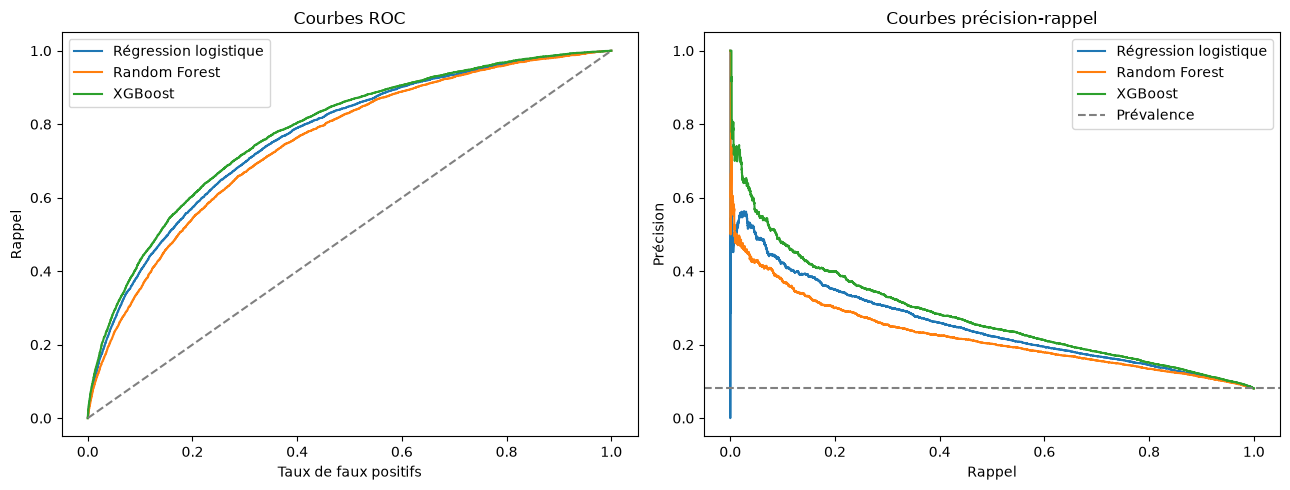


Régression logistique — matrice de confusion (lignes vraies 0/1, colonnes prédites 0/1) :


,Prédit 0,Prédit 1
Vrai 0,39485,17053
Vrai 1,1500,3465



Random Forest — matrice de confusion (lignes vraies 0/1, colonnes prédites 0/1) :


,Prédit 0,Prédit 1
Vrai 0,48604,7934
Vrai 1,2784,2181



XGBoost — matrice de confusion (lignes vraies 0/1, colonnes prédites 0/1) :


,Prédit 0,Prédit 1
Vrai 0,41584,14954
Vrai 1,1566,3399


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, scores in probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_valid, scores)
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    axes[0].plot(false_positive_rate, true_positive_rate, label=model_name)
    axes[1].plot(recall, precision, label=model_name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set(title="Courbes ROC", xlabel="Taux de faux positifs", ylabel="Rappel")
axes[1].set(title="Courbes précision-rappel", xlabel="Rappel", ylabel="Précision")
axes[1].axhline(y_valid.mean(), linestyle="--", color="grey", label="Prévalence")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

for model_name, matrix in confusion_matrices.items():
    print(f"\n{model_name} — matrice de confusion (lignes vraies 0/1, colonnes prédites 0/1) :")
    display(pd.DataFrame(matrix, index=["Vrai 0", "Vrai 1"], columns=["Prédit 0", "Prédit 1"]))

In [10]:
best_model_name = comparison.index[0]
best_pipeline = pipelines[best_model_name]
comparison.to_csv(REPORT_DIR / "home_credit_model_comparison.csv")
joblib.dump(best_pipeline, MODEL_DIR / "home_credit_best_pipeline.joblib", compress=3)
print(f"Meilleur modèle sur PR-AUC/AP : {best_model_name}")
print(f"Rapport sauvegardé : {REPORT_DIR / 'home_credit_model_comparison.csv'}")
print(f"Pipeline sauvegardé : {MODEL_DIR / 'home_credit_best_pipeline.joblib'}")

Meilleur modèle sur PR-AUC/AP : XGBoost
Rapport sauvegardé : /home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/reports/generated/home_credit_model_comparison.csv
Pipeline sauvegardé : /home/hawa-niass/Téléchargements/PLATEFORME INTELLIGENTE DE GESTION DES RISQUES BANCAIRES/models/home_credit_best_pipeline.joblib


## Limites de cette comparaison

- Un seul découpage train/validation et des hyperparamètres de départ : ce n'est pas une validation croisée ni une recherche d'hyperparamètres.
- Le seuil 0,5 est fixe et n'est pas nécessairement adapté au coût métier des faux positifs et faux négatifs.
- Le meilleur modèle est choisi sur la PR-AUC de validation ; conserver un jeu de test final indépendant pour toute estimation finale.
- Le résultat est une démonstration méthodologique sur un dataset historique, pas un score de production.